# tertiary-adjunct 02 · Holdout, 2020 to the last stored session

Run once, after the choice was made on 2013-2019 (notebook 01), for the chosen trial of each
form only. Development had already failed the protocol's gate for both forms, so the decision
was no-go before this ran. The holdout was run at the user's request, for the record.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import polars as pl
from tertiary_adjunct import Study, choose, development, doubled_costs, selection_series, sharpe

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(20)
st = Study()
P, G = st.p, st.p["go"]
DEV = (P["periods"]["start"], P["periods"]["dev_end"])
HOLD = (P["periods"]["holdout_start"], st.last_session())
dev = development(st)
chosen = choose(dev)
print("holdout", HOLD[0], "to", HOLD[1], "| chosen:", {f: c["score"] for f, c in chosen.items()})

holdout 2020-01-01 to 2026-11-19 | chosen: {'long_only': 'C1', 'long_short': 'C3'}


## 1 · The holdout run

In [2]:
hold = {f: st.backtest(f, c["score"], *HOLD) for f, c in chosen.items()}
keep = ["form", "score", "start", "end", "years", "ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover_per_year",
        "cost_drag", "market_return", "active_return", "tracking_error", "ir", "relative_drawdown"]
pl.DataFrame([{k: r.figures().get(k) for k in keep} for r in hold.values()]).with_columns(pl.col(pl.Float64).round(3))

form,score,start,end,years,ann_return,ann_vol,sharpe,max_drawdown,turnover_per_year,cost_drag,market_return,active_return,tracking_error,ir,relative_drawdown
str,str,date,date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""long_only""","""C1""",2020-01-16,2026-11-19,6.83,0.186,0.216,0.898,-0.331,5.581,0.005,0.135,0.051,0.064,0.734,-0.122
"""long_short""","""C3""",2020-01-16,2026-11-19,6.83,0.009,0.124,0.138,-0.358,16.924,0.026,null,null,null,null,null


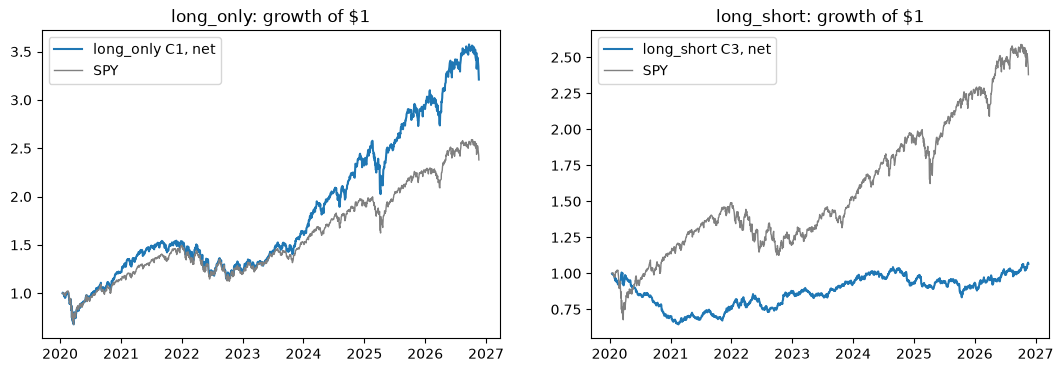

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (form, r) in zip(axes, hold.items()):
    d = r.daily.join(r.market.select("date", "ret"), on="date", how="left").sort("date")
    ax.plot(d["date"], (1 + d["net"]).cum_prod(), label=f"{form} {r.score}, net")
    ax.plot(d["date"], (1 + d["ret"].fill_null(0)).cum_prod(), label="SPY", color="grey", lw=1)
    ax.set_title(f"{form}: growth of $1")
    ax.legend()
plt.show()

In [4]:
out = []
for form, r in hold.items():
    d = r.daily.join(r.market.select("date", "ret"), on="date", how="left")
    out.append(d.group_by(pl.col("date").dt.year().alias("year"))
               .agg(((1 + pl.col("net")).product() - 1).alias("net"), ((1 + pl.col("ret")).product() - 1).alias("spy"))
               .sort("year").with_columns(pl.lit(form).alias("form"), pl.lit(r.score).alias("score")))
pl.concat(out).with_columns((pl.col("net") - pl.col("spy")).alias("net_minus_spy")).select(
    "form", "score", "year", "net", "spy", "net_minus_spy").with_columns(pl.col(pl.Float64).round(3))

form,score,year,net,spy,net_minus_spy
str,str,i32,f64,f64,f64
"""long_only""","""C1""",2020,0.223,0.151,0.072
"""long_only""","""C1""",2021,0.247,0.287,-0.04
"""long_only""","""C1""",2022,-0.193,-0.182,-0.011
"""long_only""","""C1""",2023,0.327,0.262,0.065
"""long_only""","""C1""",2024,0.422,0.249,0.173
"""long_only""","""C1""",2025,0.251,0.177,0.074
"""long_only""","""C1""",2026,0.105,0.058,0.047
"""long_short""","""C3""",2020,-0.299,0.151,-0.45
"""long_short""","""C3""",2021,0.085,0.287,-0.203


## 2 · Go or no-go

Every criterion of the protocol, for the chosen trial of each form. All must hold.

In [5]:
rows = []
for form, c in chosen.items():
    f = hold[form].figures()
    base = dev[(form, c["score"])]
    lag2 = sharpe(selection_series(st.backtest(form, c["score"], *DEV, lag=2))["r"])
    x2 = sharpe(selection_series(replace(base, daily=doubled_costs(base.daily)))["r"])
    if form == "long_short":
        checks = [("holdout net Sharpe", f["sharpe"], ">=", G["ls_holdout_sharpe"]),
                  ("holdout max drawdown", f["max_drawdown"], ">=", G["ls_max_drawdown"])]
    else:
        checks = [("holdout net IR vs SPY", f["ir"], ">=", G["lo_holdout_ir"]),
                  ("holdout net return above SPY", f["active_return"], ">=", G["lo_active_return"]),
                  ("holdout relative drawdown", f["relative_drawdown"], ">=", G["lo_max_relative_drawdown"])]
    checks += [("development deflated Sharpe", c["deflated_sharpe"], ">=", G["dev_deflated_sharpe"]),
               ("development figure, lag 2", lag2, ">", 0.0),
               ("development figure, costs x2", x2, ">", 0.0)]
    for name, v, op, t in checks:
        rows.append({"form": form, "score": c["score"], "criterion": name, "value": round(v, 3), "needs": f"{op} {t}",
                     "pass": v >= t if op == ">=" else v > t})
go = pl.DataFrame(rows)
go

form,score,criterion,value,needs,pass
str,str,str,f64,str,bool
"""long_only""","""C1""","""holdout net IR vs SPY""",0.734,""">= 0.3""",true
"""long_only""","""C1""","""holdout net return above SPY""",0.051,""">= 0.01""",true
"""long_only""","""C1""","""holdout relative drawdown""",-0.122,""">= -0.15""",true
"""long_only""","""C1""","""development deflated Sharpe""",0.137,""">= 0.9""",false
"""long_only""","""C1""","""development figure, lag 2""",-0.129,"""> 0.0""",false
"""long_only""","""C1""","""development figure, costs x2""",-0.204,"""> 0.0""",false
"""long_short""","""C3""","""holdout net Sharpe""",0.138,""">= 0.3""",false
"""long_short""","""C3""","""holdout max drawdown""",-0.358,""">= -0.2""",false
"""long_short""","""C3""","""development deflated Sharpe""",0.816,""">= 0.9""",false


In [6]:
go.group_by("form", maintain_order=True).agg(pl.col("pass").all().alias("go"), pl.col("pass").sum().alias("passed"),
                                              pl.len().alias("criteria"))

form,go,passed,criteria
str,bool,u32,u32
"""long_only""",false,3,6
"""long_short""",false,2,5


## 3 · What the holdout shows

**No-go for both forms, as the development gate had already decided.**

- **Long-short C3 also fails the holdout.**
  - Net Sharpe 0.14 (needs 0.30) and max drawdown -36% (limit -20%).
  - 2020 lost 30%: the book was long quality and value and short the names that led the rebound from the March low.
  - From 2021 it made about 7%/yr at 12% volatility, but at that rate it would take years to show.
- **Long-only C1 passes all three holdout tests: the opposite of its development years.**
  - +5.1%/yr net above SPY, information ratio 0.73, worst relative drawdown -12%.
  - Development was -1.1%/yr, so over 2013-2026 it was roughly +2%/yr above SPY.
  - The gain is concentrated in 2023-2025 (+6.5%, +17.3%, +7.4%). In those years the 5% per-name cap sat on NVDA, AAPL, META, MA and TSM: large-cap quality with momentum.
  - The protocol does not count this as a go, for three reasons:
    - the development figure was negative, not just short of significance;
    - C1 is the score the `subspace-probe` notebooks had already shown on 2013-2026, so this holdout was never unseen for it;
    - one run of seven years mostly measures one regime.
- **The only clean test left is paper trading.** A paper test of long-only C1 would need a new protocol, written before it starts, with its own length and pass rules.